### PART - A

## Import and load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
dataset = sns.load_dataset('titanic')

##  1 - Figure and Axes , age histogram

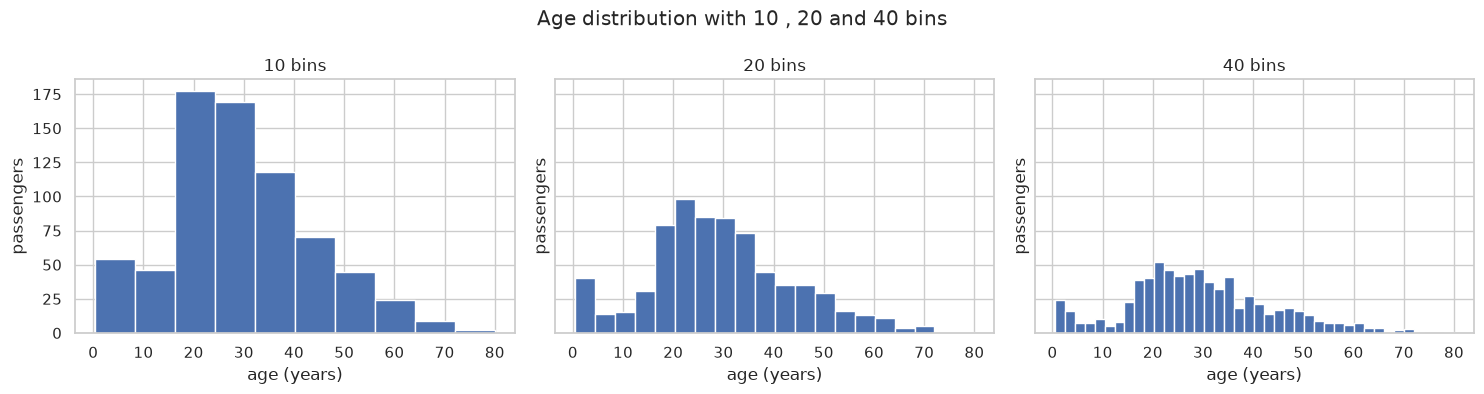

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, bins in zip(axes, [10, 20, 40]):
    ax.hist(dataset['age'].dropna(), bins=bins, color='#4c72b0', edgecolor='white')
    ax.set_title(f'{bins} bins')
    ax.set_xlabel('age (years)')
    ax.set_ylabel('passengers')

fig.suptitle('Age distribution with 10 , 20 and 40 bins')
fig.tight_layout()
plt.show()

# note to self : fig is the whole canvas , axes are the 3 boxes , sharey makes the 3 panels comparable

**What I see :** the age distribution is unimodal around 25-30 years with a small bump under 10 , and the shape is the same with 10 , 20 or 40 bins , only the noise changes.

**What it means :** age is slightly right-skewed (mean 29.7 > median 28) , and the 177 missing ages are simply absent from the plot.

**Limit :** a histogram pools every passenger , it hides the split by sex or class that actually drives survival.

##  2 - Passengers per class

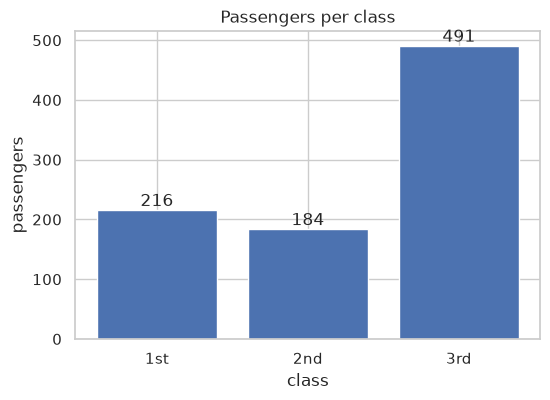

In [4]:
counts = dataset['pclass'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['1st', '2nd', '3rd'], counts.values, color='#4c72b0')
ax.bar_label(bars)
ax.set_title('Passengers per class')
ax.set_xlabel('class')
ax.set_ylabel('passengers')
plt.show()

# note to self : the heights are counts here , not rates , the labels avoid the classic "bar without numbers" trap

**What I see :** 491 passengers in 3rd class against 216 in 1st and 184 in 2nd , so more than half of the ship is 3rd class.

**What it means :** every class comparison has to be read with these counts , a rate computed on 184 people is noisier than one computed on 491.

**Limit :** counts say nothing about survival , the rates come in part B.

##  3 - Age against fare

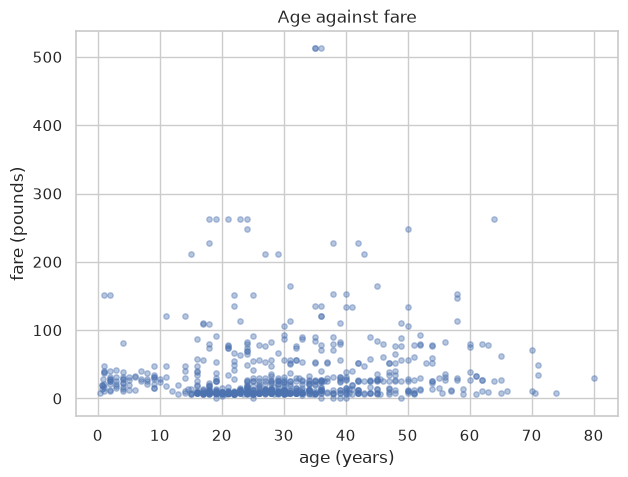

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(dataset['age'], dataset['fare'], s=15, alpha=0.4, color='#4c72b0')
ax.set_title('Age against fare')
ax.set_xlabel('age (years)')
ax.set_ylabel('fare (pounds)')
plt.show()

# note to self : matplotlib drops the NaN points silently , so the 177 missing ages are missing from this plot too

**What I see :** most points sit below 40 years and below 100 pounds , with a handful of fares above 250 and a hard ceiling at 512.

**What it means :** fare is heavily right-skewed and almost independent from age (r = 0.10).

**Limit :** the overplotting hides where the density really is , a log y-axis or a 2D histogram would read better.

##  4 - A 2x2 grid

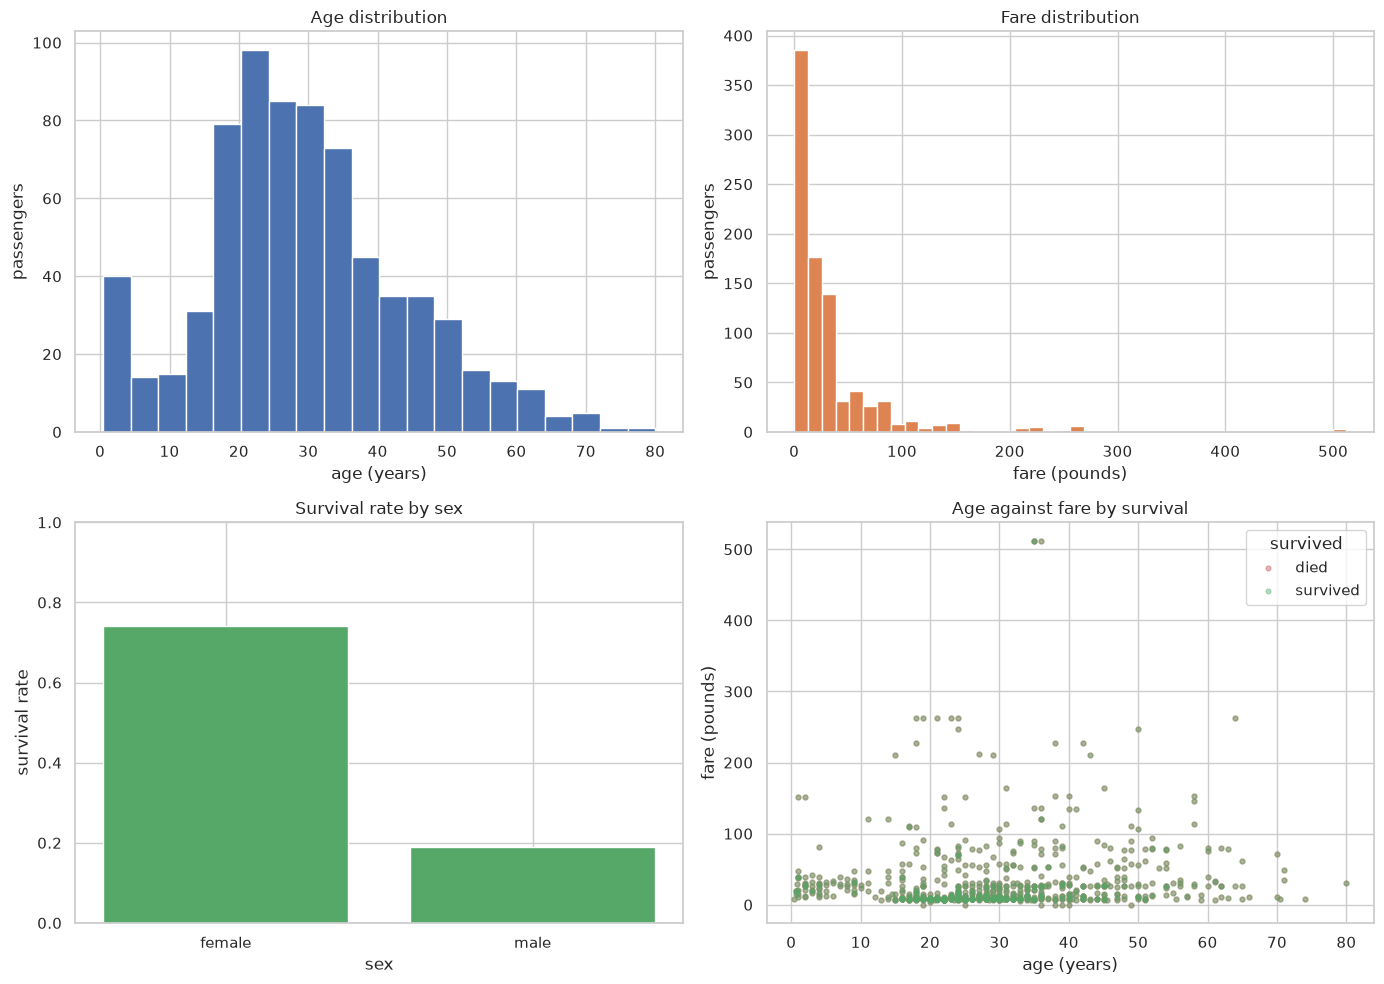

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(dataset['age'].dropna(), bins=20, color='#4c72b0', edgecolor='white')
axes[0, 0].set_title('Age distribution')
axes[0, 0].set_xlabel('age (years)')
axes[0, 0].set_ylabel('passengers')

axes[0, 1].hist(dataset['fare'], bins=40, color='#dd8452', edgecolor='white')
axes[0, 1].set_title('Fare distribution')
axes[0, 1].set_xlabel('fare (pounds)')
axes[0, 1].set_ylabel('passengers')

survival_by_sex = dataset.groupby('sex')['survived'].mean()
axes[1, 0].bar(survival_by_sex.index, survival_by_sex.values, color='#55a868')
axes[1, 0].set_title('Survival rate by sex')
axes[1, 0].set_xlabel('sex')
axes[1, 0].set_ylabel('survival rate')
axes[1, 0].set_ylim(0, 1)

for survived, label, color in [(0, 'died', '#c44e52'), (1, 'survived', '#55a868')]:
    axes[1, 1].scatter(dataset['age'], dataset['fare'], s=12, alpha=0.4, label=label, color=color)

axes[1, 1].set_title('Age against fare by survival')
axes[1, 1].set_xlabel('age (years)')
axes[1, 1].set_ylabel('fare (pounds)')
axes[1, 1].legend(title='survived')

fig.tight_layout()
plt.show()

# note to self : four different questions on one canvas , each panel keeps its own title , labels and scale

**What I see :** four panels , the age distribution , the fare distribution , the survival rate by sex and age against fare coloured by survival.

**What it means :** the sex panel separates the two groups immediately , while the scatter shows that survivors are not separated by age.

**Limit :** each panel has its own scale so the bars cannot be compared across panels , and every panel drops the missing ages.

### PART - B

##  1 - How is age distributed ?

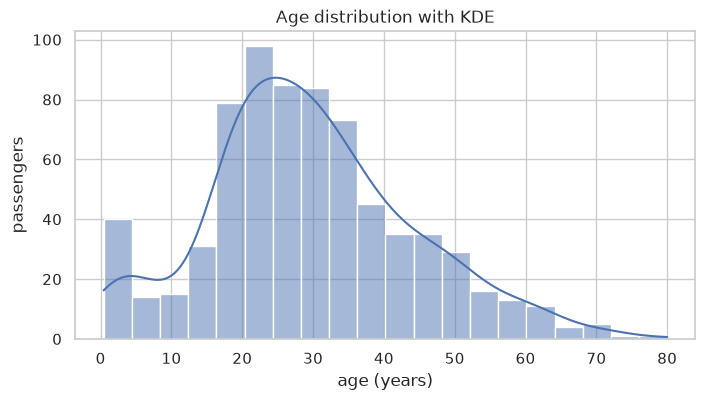

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(dataset['age'], bins=20, kde=True, ax=ax)
ax.set_title('Age distribution with KDE')
ax.set_xlabel('age (years)')
ax.set_ylabel('passengers')
plt.show()

**What I see :** a main peak around 25 years , a small bump for young children and a long thin tail up to 80.

**What it means :** the median (28) is a better summary than the mean (29.7) , and children are a small but distinct group.

**Limit :** the KDE smooths over the 177 missing ages and can suggest values outside the real range.

##  2 - How is fare distributed ?

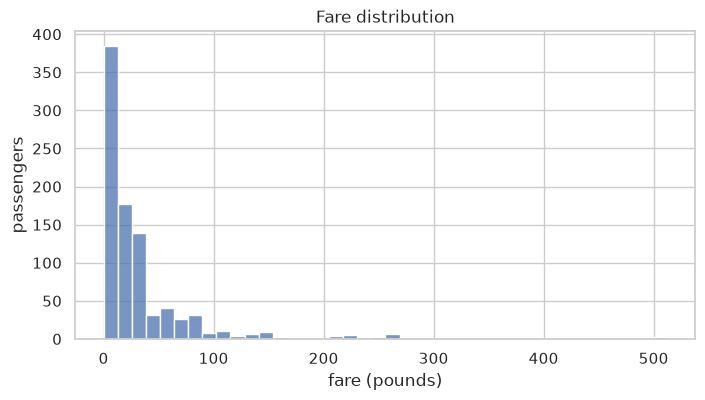

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(dataset['fare'], bins=40, ax=ax)
ax.set_title('Fare distribution')
ax.set_xlabel('fare (pounds)')
ax.set_ylabel('passengers')
plt.show()

**What I see :** almost every fare is below 50 , with a long tail up to 512 and 3 passengers at the maximum.

**What it means :** median 14.45 against mean 32.20 , the mean is pulled by a few very expensive tickets (99% of fares are below 249).

**Limit :** on a linear axis the tail crushes the mass of the distribution , a log scale shows it better (part C).

##  3 - Are there fare outliers by class ?

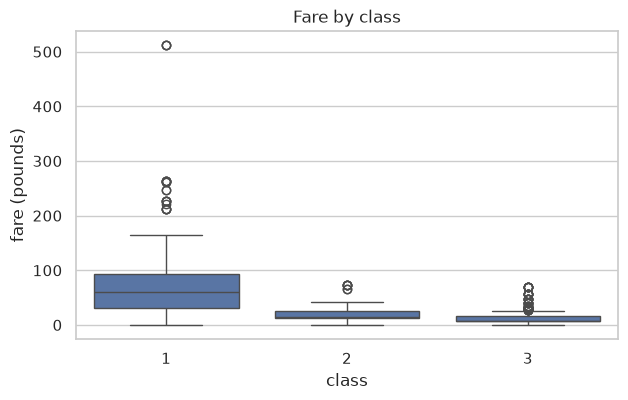

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=dataset, x='pclass', y='fare', ax=ax)
ax.set_title('Fare by class')
ax.set_xlabel('class')
ax.set_ylabel('fare (pounds)')
plt.show()

# note to self : the box is Q1 - median - Q3 , the whiskers go to 1.5 IQR and the dots are the outliers

**What I see :** median fare 60.3 in 1st , 14.25 in 2nd and 8.05 in 3rd , and the 1st class box is much wider with many high outliers.

**What it means :** class and fare carry the same information (r = -0.55) , and the expensive outliers are all in 1st class.

**Limit :** the boxes hide the counts per class , 216 rows in 1st against 491 in 3rd.

##  4 - Is the target balanced ?

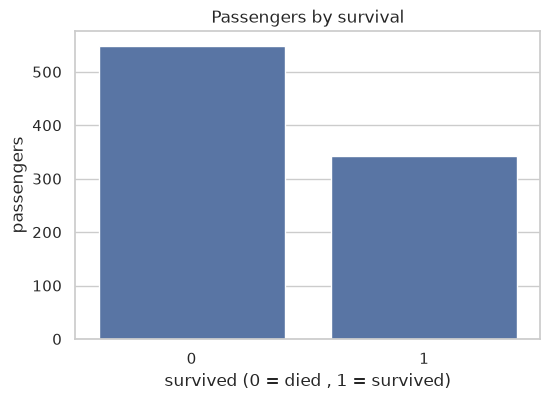

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=dataset, x='survived', ax=ax)
ax.set_title('Passengers by survival')
ax.set_xlabel('survived (0 = died , 1 = survived)')
ax.set_ylabel('passengers')
plt.show()

# note to self : the bars are raw counts , i add the labels so nobody has to guess the numbers

**What I see :** 549 died against 342 survived , so the target is 61.6% / 38.4%.

**What it means :** the classes are not balanced , a model that always answers "died" already scores 61.6% accuracy , so accuracy alone is a trap.

**Limit :** the plot says nothing about which subgroups survive , only the overall ratio.

##  5 - Does sex influence survival ?

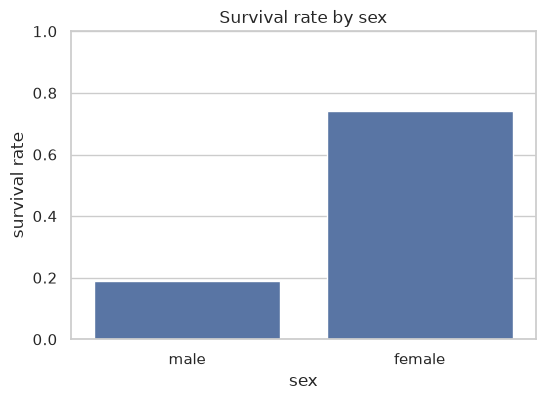

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=dataset, x='sex', y='survived', errorbar=None, ax=ax)
ax.set_title('Survival rate by sex')
ax.set_xlabel('sex')
ax.set_ylabel('survival rate')
ax.set_ylim(0, 1)
plt.show()

# note to self : seaborn puts the mean of survived on the y axis , so the bar height is the survival rate , errorbar=None removes the CI

**What I see :** the survival rate is 0.742 for women against 0.189 for men.

**What it means :** sex is the strongest single split in the dataset , and the bar height is just the mean of a 0 / 1 column.

**Limit :** it averages over class , and the gap is not the same in 1st and 3rd class (next charts).

##  6 - Does class influence survival ?

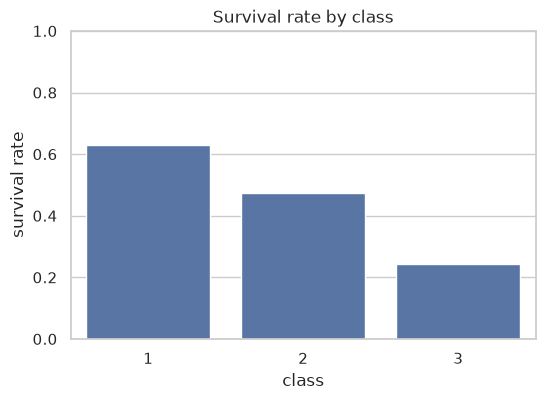

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=dataset, x='pclass', y='survived', errorbar=None, ax=ax)
ax.set_title('Survival rate by class')
ax.set_xlabel('class')
ax.set_ylabel('survival rate')
ax.set_ylim(0, 1)
plt.show()

**What I see :** 0.630 in 1st , 0.473 in 2nd and 0.242 in 3rd , a monotone decrease.

**What it means :** class matters independently of sex , and because it is ordered 1 > 2 > 3 an ordinal encoding is meaningful.

**Limit :** the bars average men and women together , which hides the interaction.

##  7 - Is the class effect the same for both sexes ?

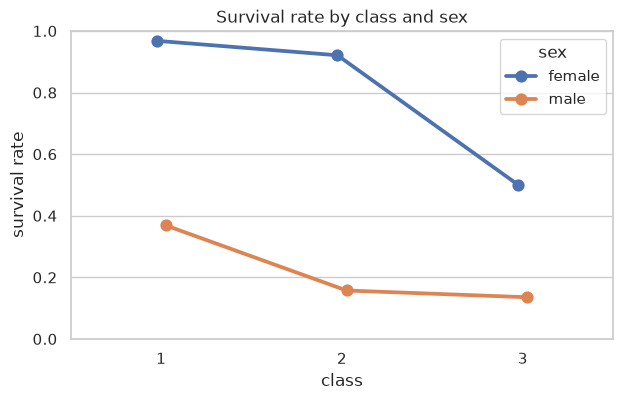

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.pointplot(data=dataset, x='pclass', y='survived', hue='sex', errorbar=None, dodge=True, ax=ax)
ax.set_title('Survival rate by class and sex')
ax.set_xlabel('class')
ax.set_ylabel('survival rate')
ax.set_ylim(0, 1)
plt.show()

**What I see :** women go from 0.968 in 1st to 0.921 in 2nd to 0.500 in 3rd , while men stay low at 0.369 / 0.157 / 0.135.

**What it means :** the class effect exists in both sexes but is much stronger for women , so sex and class interact.

**Limit :** the point plot hides the sample size behind each point and the uncertainty around each rate.

##  8 - Does age separate survivors ?

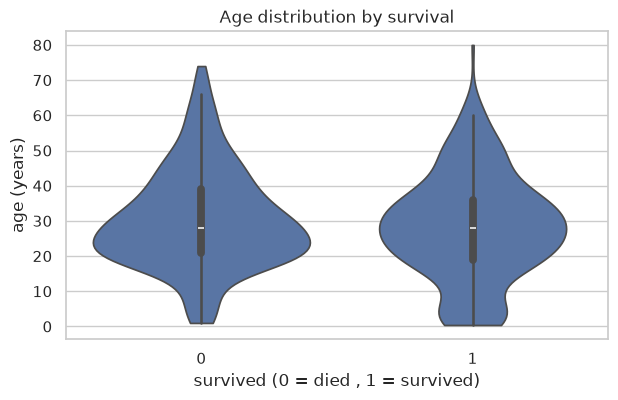

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.violinplot(data=dataset, x='survived', y='age', cut=0, ax=ax)
ax.set_title('Age distribution by survival')
ax.set_xlabel('survived (0 = died , 1 = survived)')
ax.set_ylabel('age (years)')
plt.show()

# note to self : cut=0 stops the KDE from inventing ages outside the observed range

**What I see :** the two violins have almost the same shape , median age 28 in both groups , with a slightly fatter child bump for survivors (11.4% under 12 against 5.3%).

**What it means :** age alone separates survivors very little , the only visible signal is that children survive a bit more.

**Limit :** the violin hides the exact counts per group and drops the 177 missing ages.

##  9 - Age against fare , by class

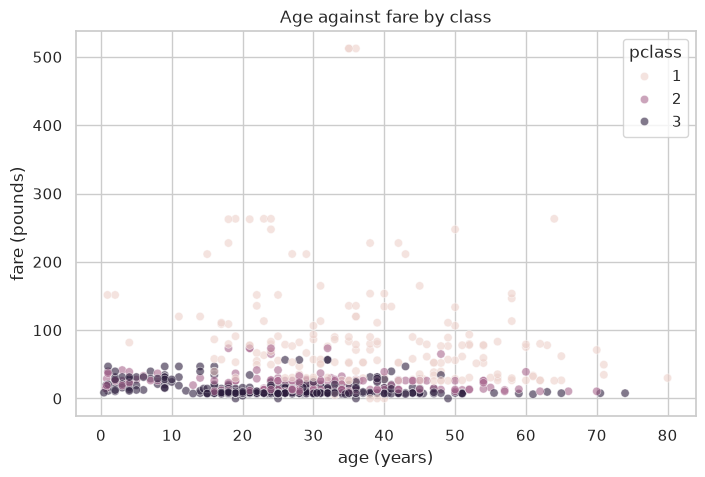

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=dataset, x='age', y='fare', hue='pclass', alpha=0.6, ax=ax)
ax.set_title('Age against fare by class')
ax.set_xlabel('age (years)')
ax.set_ylabel('fare (pounds)')
plt.show()

**What I see :** the expensive fares are all in 1st class , 2nd and 3rd sit in a low band , and age does not move the fare inside a class.

**What it means :** fare is mostly a proxy of class , which explains its correlation with survival (0.26) without being a cause.

**Limit :** the overplotting hides the density and the linear correlation is dominated by the fare tail.

##  10 - Which variables are linked ?

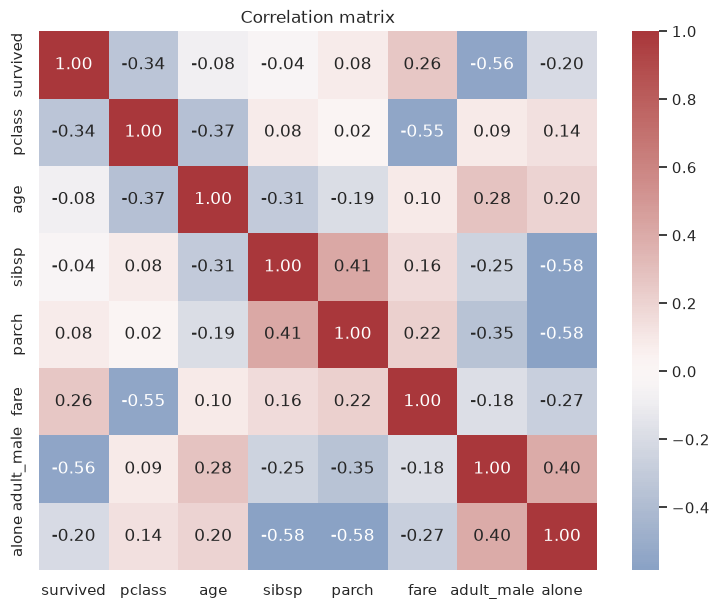

In [16]:
corr = dataset.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', center=0, cmap='vlag', ax=ax)
ax.set_title('Correlation matrix')
plt.show()

**What I see :** survived correlates -0.56 with adult_male , -0.34 with pclass , +0.26 with fare , -0.20 with alone and only -0.08 with age ; pclass and fare are at -0.55 , sibsp and parch at +0.41.

**What it means :** the strongest feature is a duplicate of sex , the real drivers are sex (via adult_male) , class and fare , and those three are themselves correlated.

**Limit :** Pearson only sees linear links and ignores the categorical sex column , so this matrix is not the whole story.

##  11 - Where are the missing values ?

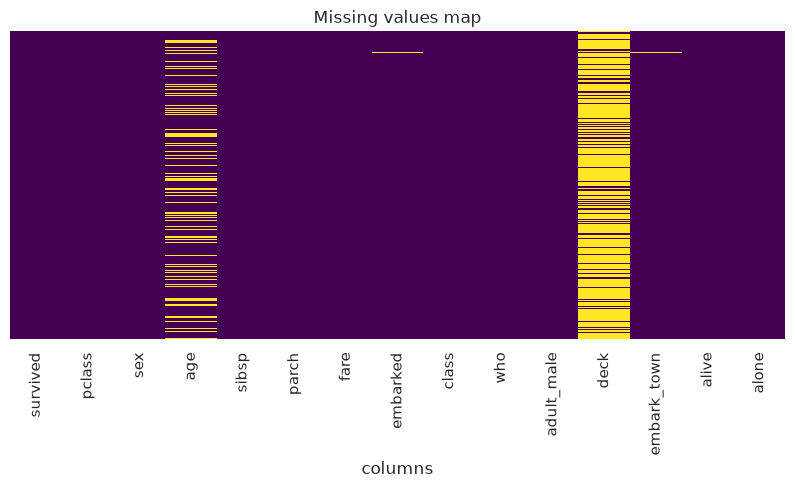

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(dataset.isna(), cbar=False, yticklabels=False, cmap='viridis', ax=ax)
ax.set_title('Missing values map')
ax.set_xlabel('columns')
plt.show()

**What I see :** deck is missing in a huge 77% block , age in a scattered 20% band , and embarked / embark_town miss only 2 rows.

**What it means :** deck is not missing at random (a cabin was only recorded for some passengers) and is almost unusable , age needs imputation , and the 2 embarked rows can be dropped.

**Limit :** the map does not show whether the age holes are linked to class or to survival , that needs a groupby.

##  12 - Pairplot of the numeric variables

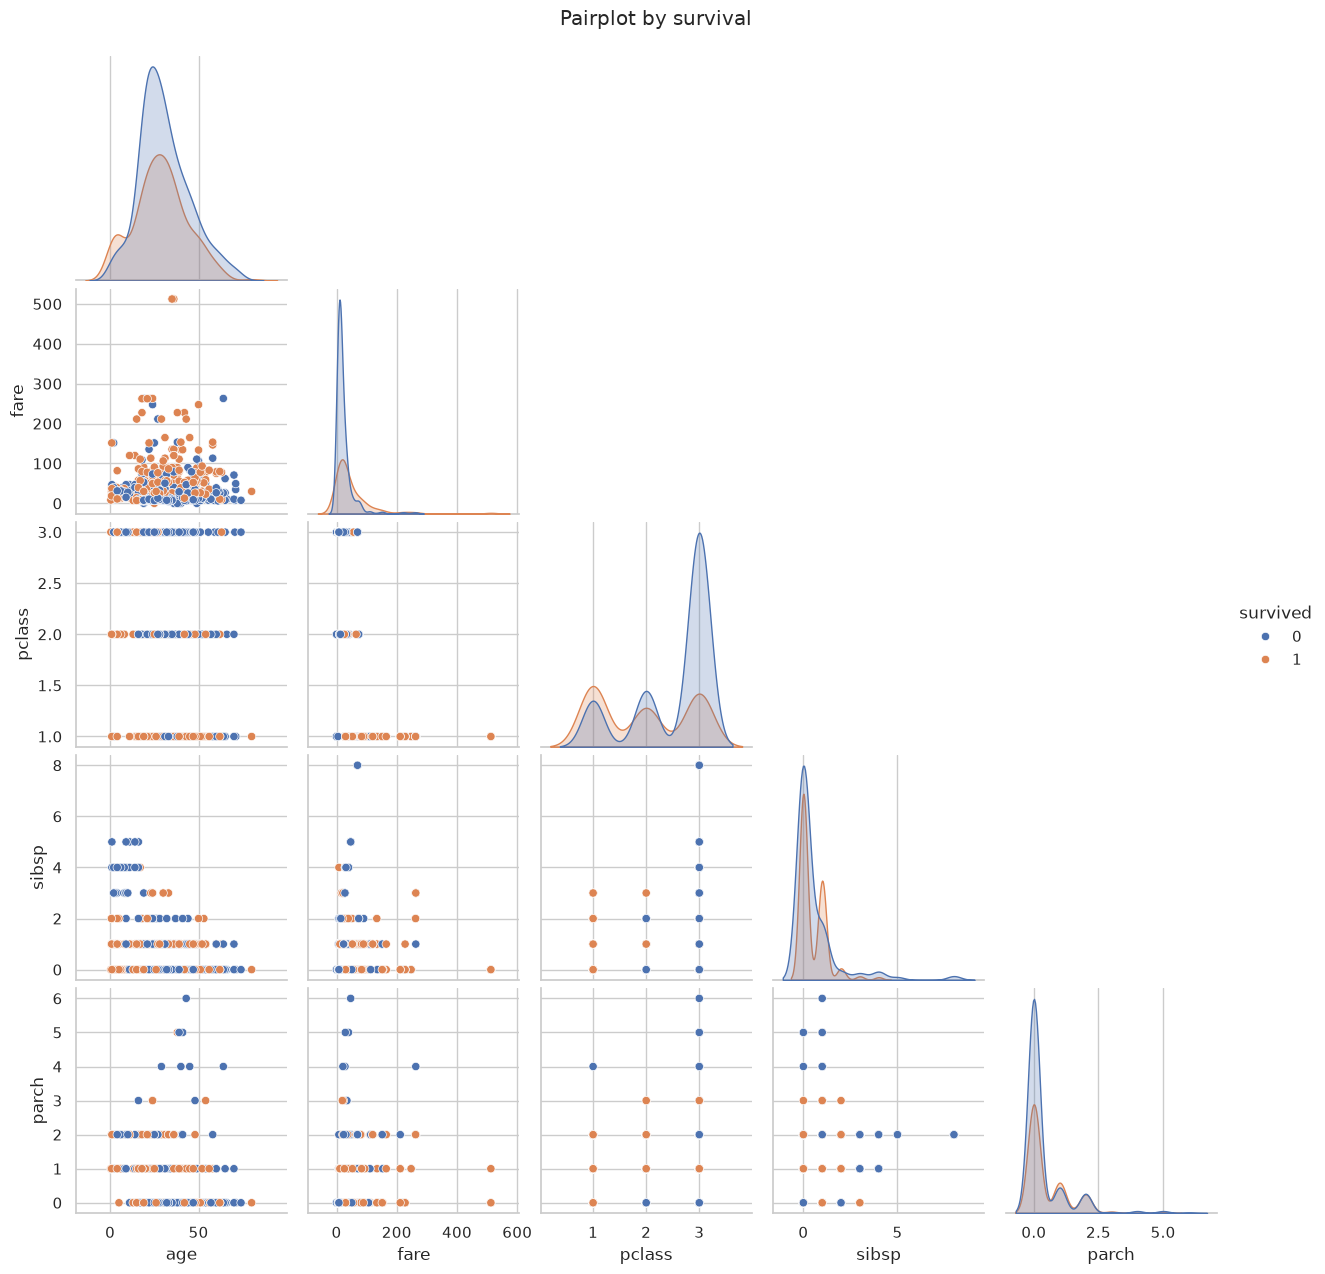

In [18]:
g = sns.pairplot(
    dataset[['survived', 'age', 'fare', 'pclass', 'sibsp', 'parch']],
    hue='survived',
    corner=True,
    diag_kind='kde',
)
g.fig.suptitle('Pairplot by survival', y=1.02)
plt.show()

**What I see :** survivors and dead overlap almost completely on age , while fare and pclass show a clearer separation , with survivors more often in the higher classes.

**What it means :** the pairplot confirms the ranking sex > class > fare > age before any modelling.

**Limit :** with 891 points the KDEs are rough , and sex is absent because it is not numeric.